# Experiment: regimes that differ only in their spectrum

**Data.** A univariate series is a sum of three pure sinusoids plus white noise. Each of the K = 4 regimes has its own three frequencies and the same amplitudes, so the mean and variance are identical in every regime and only the spectrum changes. The phases stay continuous through each switch, so a change is never a visible jump.

**Protocol.**
1. Fit every available feature learner on fresh samples of the dataset:
   - the fixed raw-window baselines and the clean-signal oracle;
   - all LeJEPA variants;
   - AE, VAE, β-VAE, and the AE and VAE with a **linear predictor in latent space** (`ae_pred`, `vae_pred`);
   - CPC and TS2Vec.
2. Compute every learner's features on the fixed test split.
3. Run every registered detector on those features:
   - regime clustering: GMM, HMM, AR-HMM, temporal excess;
   - change-point detection: contrast, MMD, BOCPD, DMD error, CPDMD.
4. Score at sample level: clustering accuracy for the clustering detectors (chance = 0.25), change-point AP / F1 / covering for all of them.

Everything is cached per learner and detector under `RUNS`, so re-running the notebook only computes what is new.

**Cost.** With `QUICK = False` this trains 12 networks. Run it when the machine is free, or move the training to HPC with `cpbench/hpc/make_sweep.py`. `QUICK = True` is a two-minute plumbing check (20 training steps, tiny splits) whose numbers mean nothing.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cpbench import Benchmark, make_learner, make_detector, viz
from cpbench.data import Dataset
from cpbench.features import LEARNERS
from cpbench.detectors import DETECTORS
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", message="FastICA did not converge")

QUICK = os.environ.get("CPBENCH_QUICK") == "1"     # ✏️ True: plumbing check only (20 steps, tiny splits)
RUNS = "cpbench_runs_sines" + ("_quick" if QUICK else "")
OUT = "cpbench_results/sines_experiment" + ("_quick" if QUICK else "") + ".csv"
print("QUICK" if QUICK else "full run", "->", RUNS)

full run -> cpbench_runs_sines


## 1. Dataset

`FREQS[k]` lists the three frequencies (cycles per sample) of regime k. Each `oscillator` channel is a pure sine (`damp=1, sigma=0, amplitude=1`) whose frequency follows the regime. The inner `linear` transform sums the three sines into one channel, and `noise` adds white noise. Standardisation is applied at the end.

The window is a model hyperparameter (in samples). With W = 64 the spectral resolution is 1/64 ≈ 0.016 cycles per sample, finer than the closest pair of frequencies across regimes (0.015 apart). A segment lasts 640 samples on average, about 10 windows.

In [2]:
# ✏️ the experiment's dataset
FREQS = [[0.020, 0.070, 0.150],        # regime 0
         [0.035, 0.090, 0.200],        # regime 1
         [0.050, 0.110, 0.170],        # regime 2
         [0.030, 0.130, 0.240]]        # regime 3
DATASET = dict(
    regime=dict(type="markov", K=len(FREQS), dwell=640),
    sources=[dict(type="composite",
                  sources=[dict(type="oscillator", d=3, freq=FREQS, damp=1.0, sigma=0.0, amplitude=1.0)],
                  transforms=[dict(type="linear", weights=[[1, 1, 1]])])],      # sum of the three sines
    transforms=[dict(type="noise", sigma=0.3)],
    seed=0,
    splits=dict(test=[2, 4000], val=[2, 4000]) if QUICK else dict(test=[8, 32000], val=[4, 16000]),
)
W, GAP = 64, 64                         # ✏️ window and context-target gap (samples)
ds = Dataset(DATASET)
data = ds.test_set()
print(ds.info.id)
print(f"K={ds.K}, D={ds.D}, test split {data['obs'].shape}")

markov(dwell=640)|[oscillator(amplitude=1,d=3,damp=1,freq=[[0.02,0.07,0.15],[0.035,0.09,0.2],[0.05,0.11,0.17],[0.03,0.13,0.24]],sigma=0)|linear(weights=[[1,1,1]])]|-|noise(sigma=0.3)#f287231f
K=4, D=1, test split (8, 32000, 1)


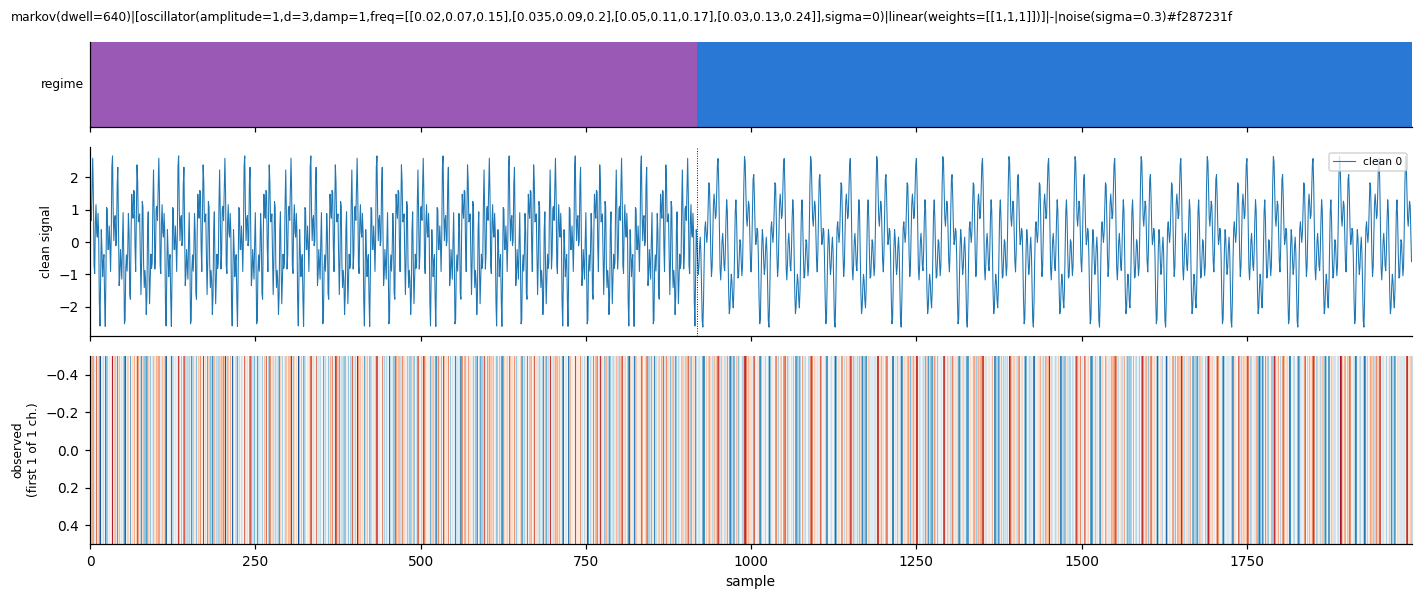

In [3]:
viz.plot_dataset(ds, data, series=0, n=2000)

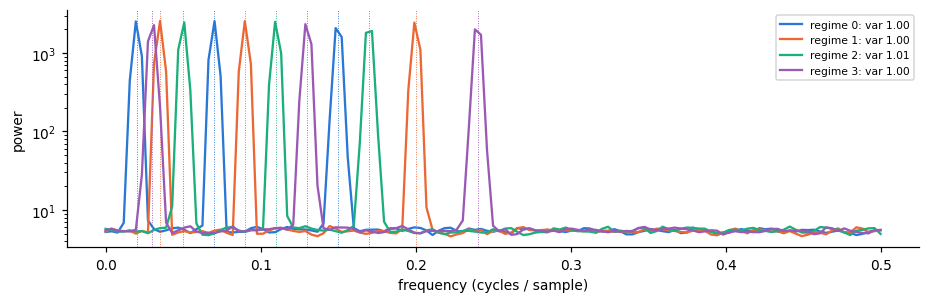

In [4]:
# check: per-regime variance and power spectrum of the test split (only the spectrum should differ)
x, S, L = data["obs"][..., 0], data["S_s"], 256
f = np.fft.rfftfreq(L)
fig, ax = plt.subplots(figsize=(10, 2.8))
for k in range(ds.K):
    segs = [x[r, t:t + L] for r in range(len(x)) for t in range(0, x.shape[1] - L, L // 2) if (S[r, t:t + L] == k).all()]
    if not segs:
        continue
    P = np.mean([np.abs(np.fft.rfft(s * np.hanning(L))) ** 2 for s in segs], 0)
    ax.semilogy(f, P, color=viz.COLORS[k], label=f"regime {k}: var {np.var(np.concatenate(segs)):.2f}")
    for fr in FREQS[k]:
        ax.axvline(fr, color=viz.COLORS[k], lw=0.6, ls=":")
ax.set_xlabel("frequency (cycles / sample)"); ax.set_ylabel("power"); ax.legend(fontsize=7); plt.show()

## 2. Feature learners and detectors

All registered feature learners are used, except the generic bases (`raw`, `oracle`, `jepa`), which their presets already cover, `oracle_hidden`, which needs a hidden state this dataset does not have, and on a univariate series `raw_lagcov`, which measures which channel leads another.
- Every learner uses the same window W.
- The learners trained on (context, target) pairs also get the gap.
- `oracle_clean` computes the window *spectrum* of the noise-free sum of sines: a ceiling, not a competitor. Its default statistic (mean, variance, …) is identical in every regime here by construction.
- **Control:** `jepa_shared` with `steps=0`, a randomly initialised encoder. A random convolutional encoder already separates spectra to some degree, so a trained learner only counts if it beats this control.

Every registered detector runs with its default parameters, which the ✏️ cell can override. The defaults suit sequences of window features (T = 500 windows per test series here).

In [5]:
SKIP = {"raw", "oracle", "jepa", "oracle_hidden"}
if ds.D == 1:
    SKIP.add("raw_lagcov")              # lead-lag between channels: undefined on one channel
print("feature learners:", [n for n in LEARNERS.available() if n not in SKIP])
print("detectors:       ", DETECTORS.available())

feature learners: ['ae', 'ae_pred', 'bvae4', 'cpc', 'jepa_mlp_separate', 'jepa_mlp_shared', 'jepa_separate', 'jepa_separate_full', 'jepa_shared', 'oracle_clean', 'raw_bispec', 'raw_coskew', 'raw_cov', 'raw_flat', 'raw_mean', 'raw_spectra', 'raw_stats', 'ts2vec', 'vae', 'vae_pred']
detectors:        ['arhmm', 'bocpd', 'contrast', 'cpdmd', 'dmd_error', 'gmm', 'hmm', 'mmd', 'temporal_excess']


In [6]:
# ✏️ training settings (workers / device / logging do not change the result)
STEPS = 20 if QUICK else 3000
TRAIN = dict(steps=STEPS, batch=128, workers=0 if QUICK else 1, eval_every=max(STEPS // 4, 5), warmup=min(1000, STEPS))

def learner(name, **extra):
    defaults = LEARNERS.defaults(name)
    p = dict(window=W)
    if "gap" in defaults:
        p["gap"] = GAP
    if "steps" in defaults:
        p.update(TRAIN)
    if name == "oracle_clean":
        p["feature"] = "spectra"         # the regimes differ only in their spectrum
    return make_learner(name, **{**p, **extra})

FEATURES = [learner(n) for n in LEARNERS.available() if n not in SKIP]
FEATURES.append(learner("jepa_shared", steps=0))   # control: untrained (random) encoder
FIXED = [f for f in FEATURES if not f.trainable]
LEARNT = [f for f in FEATURES if f.trainable]

# ✏️ detectors: every registered one, with optional parameter overrides
OVERRIDES = {}                          # e.g. {"bocpd": dict(hazard=0.1), "cpdmd": dict(w=40, d=10, r=4)}
DETS = [dict(type=n, **OVERRIDES.get(n, {})) for n in DETECTORS.available()]
print(len(FIXED), "fixed and", len(LEARNT), "trained feature learners;", len(DETS), "detectors")

8 fixed and 13 trained feature learners; 9 detectors


## 3. Fit, extract features, detect

The fixed learners run first. Each trained learner is then fitted, or loaded if `RUNS` already holds it, and every detector runs on its features. Results go to `OUT` after each learner, so an interrupted run keeps what it finished.

In [7]:
bench = Benchmark(ds, detectors=DETS, out=RUNS, log=lambda *a: None)
results = []
for f in FIXED + LEARNT:
    results.append(bench.run(f))
    pd.concat(results, ignore_index=True).to_csv(OUT, index=False)
    r = results[-1]; r = r[(r.view == "features") & r.metric.isin(["acc", "cp_ap"])]
    print(f"{f.label():<40}", "  ".join(f"{m} max {r[r.metric == m].value.max():.2f}" for m in ("acc", "cp_ap")))
res = pd.concat(results, ignore_index=True)

oracle_clean(window=64, feature=spectra) acc max 0.97  cp_ap max 0.76
raw_bispec(window=64)                    acc max 0.97  cp_ap max 0.79
raw_coskew(window=64)                    acc max 0.49  cp_ap max 0.06
raw_cov(window=64)                       acc max 0.30  cp_ap max 0.04
raw_flat(window=64)                      acc max 0.97  cp_ap max 0.84
raw_mean(window=64)                      acc max 0.51  cp_ap max 0.07
raw_spectra(window=64)                   acc max 0.97  cp_ap max 0.80
raw_stats(window=64)                     acc max 0.64  cp_ap max 0.43
ae(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.86
ae_pred(window=64, gap=64, steps=3000, batch=128) acc max 0.71  cp_ap max 0.44
bvae4(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.56
cpc(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.81
jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.82
jepa_mlp_shared(window=64, gap=64, steps=3000,

/Users/jq23948/anaconda3/lib/python3.11/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/Users/jq23948/anaconda3/lib/python3.11/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


jepa_separate_full(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.60
jepa_shared(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.84


/Users/jq23948/anaconda3/lib/python3.11/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/Users/jq23948/anaconda3/lib/python3.11/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


ts2vec(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.84
vae(window=64, gap=64, steps=3000, batch=128) acc max 0.97  cp_ap max 0.90
vae_pred(window=64, gap=64, steps=3000, batch=128) acc max 0.95  cp_ap max 0.53
jepa_shared(window=64, gap=64, steps=0, batch=128) acc max 0.97  cp_ap max 0.79


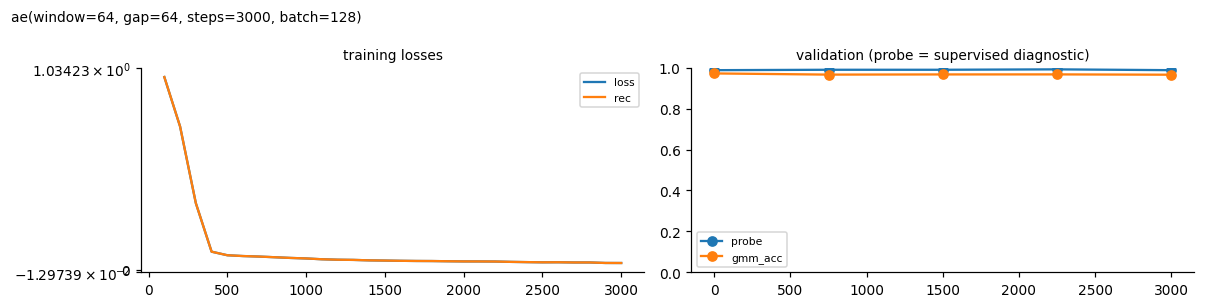

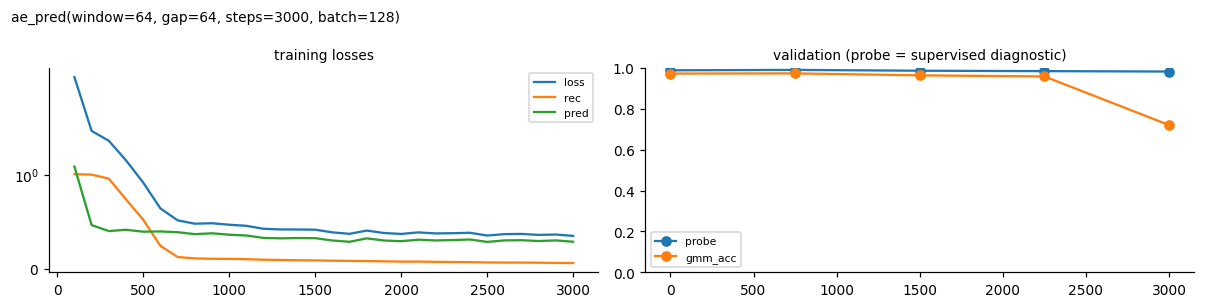

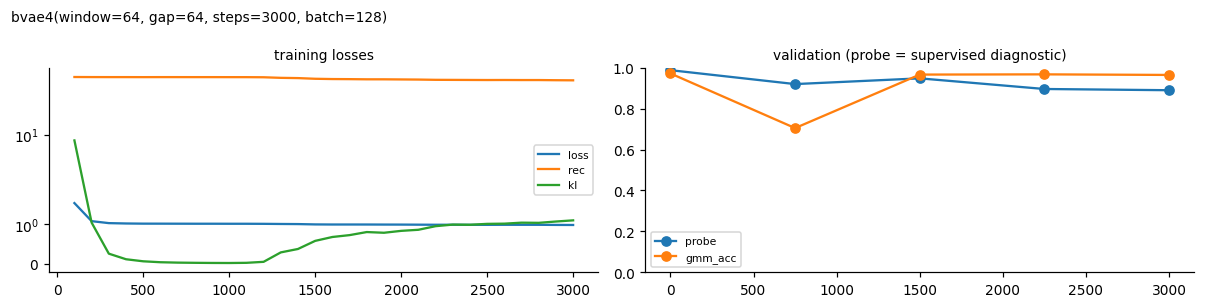

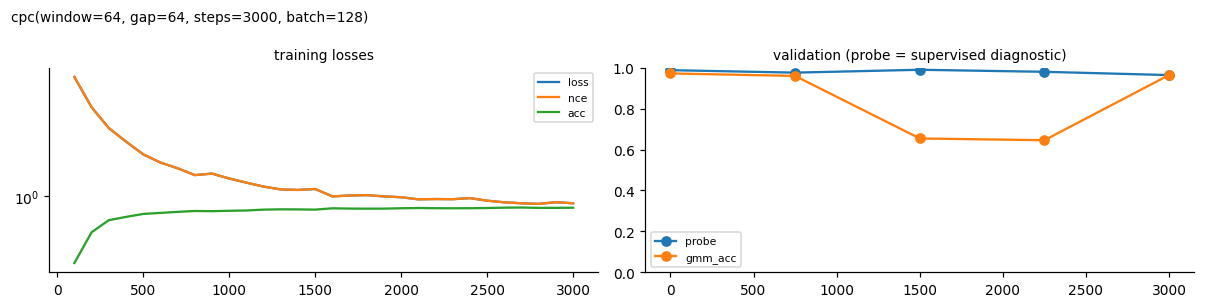

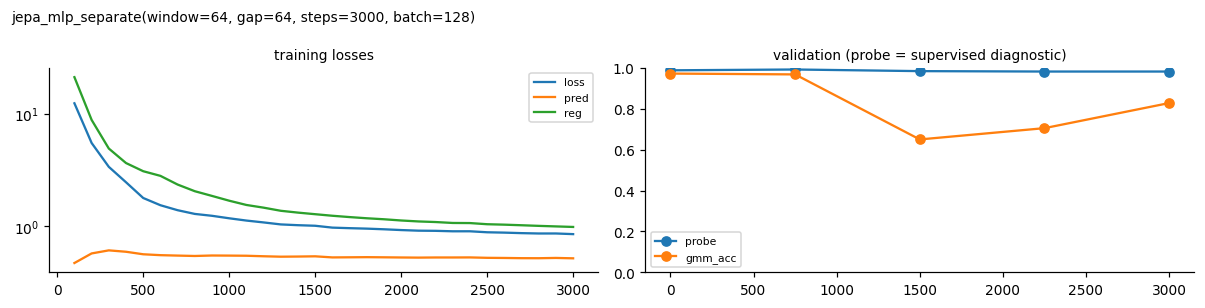

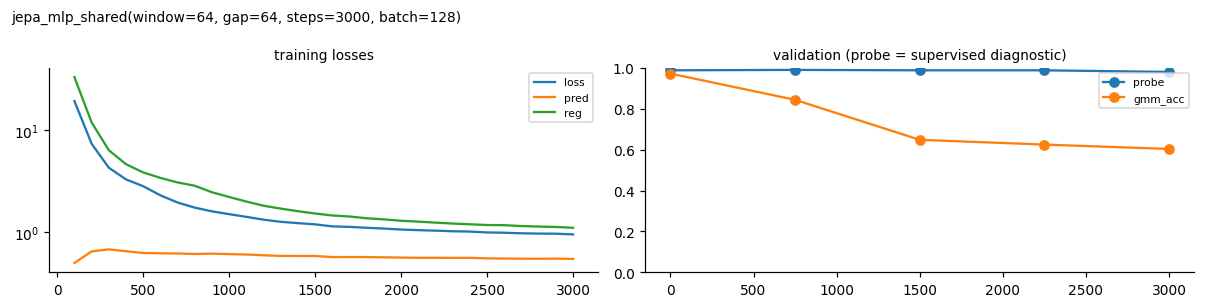

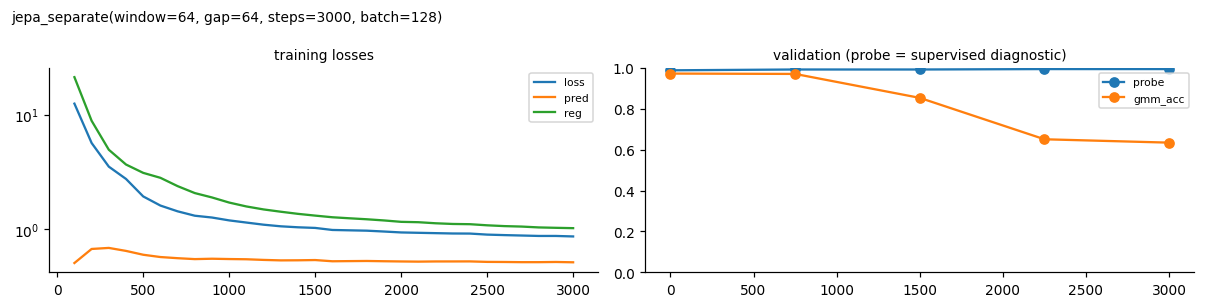

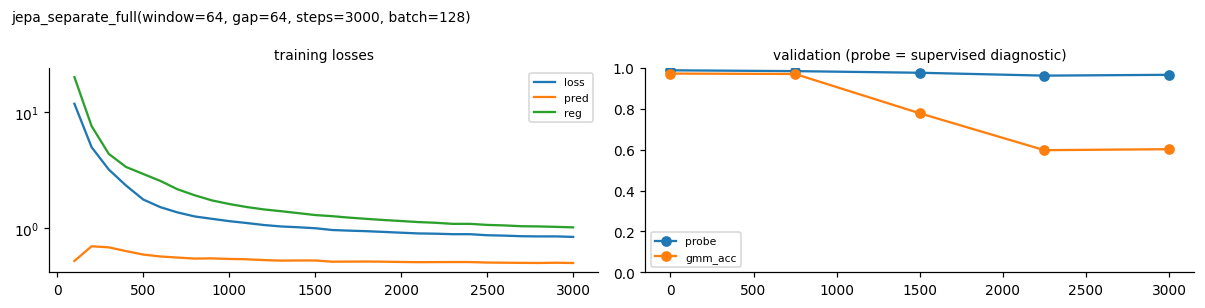

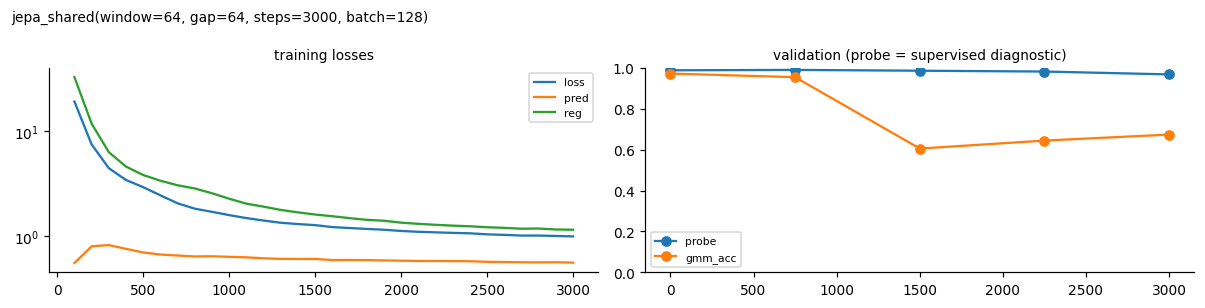

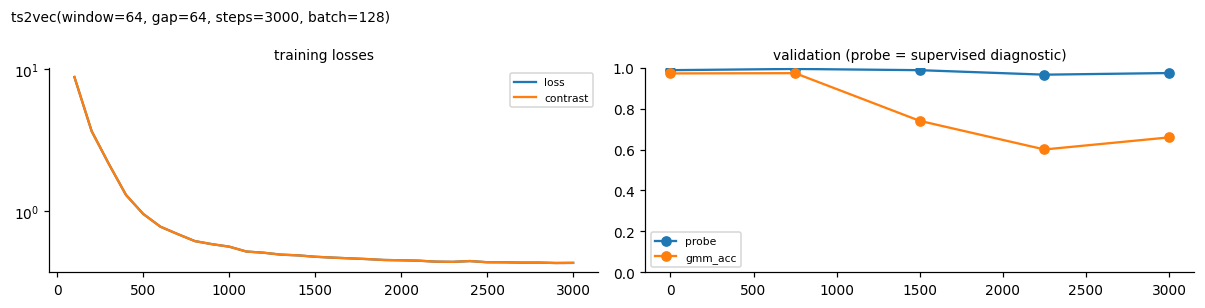

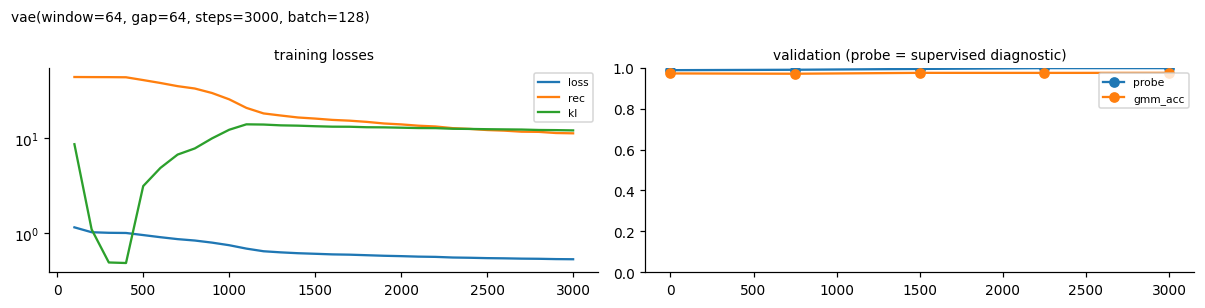

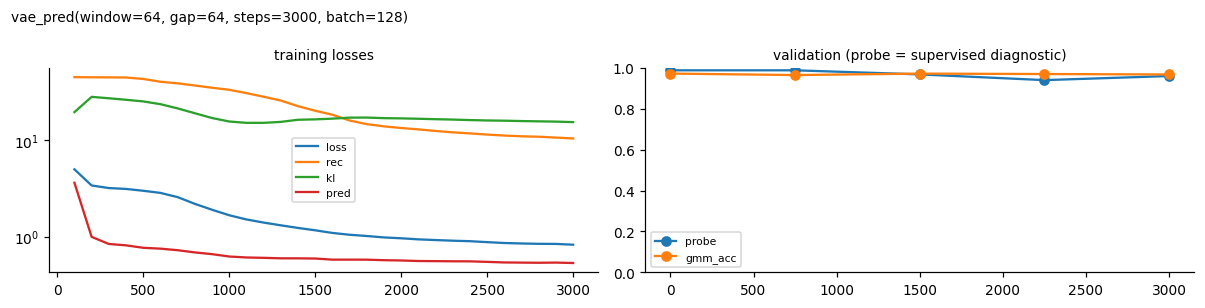

no training log (fixed feature learner?)


In [8]:
# training curves of the trained learners (losses; validation probe and GMM accuracy)
for f in LEARNT:
    viz.plot_training(bench.run_dir(f), title=f.label())

## 4. Results

The heatmaps show every feature learner × detector:
- `acc`: sample-level clustering accuracy after the best label permutation (chance 0.25);
- `cp_ap`: change-point average precision;
- `cp_f1`: F1 at the default threshold, or at the detector's own alarms (CPDMD).

Change-point detectors have no `acc`. Rows are the feature learners and columns the detectors.

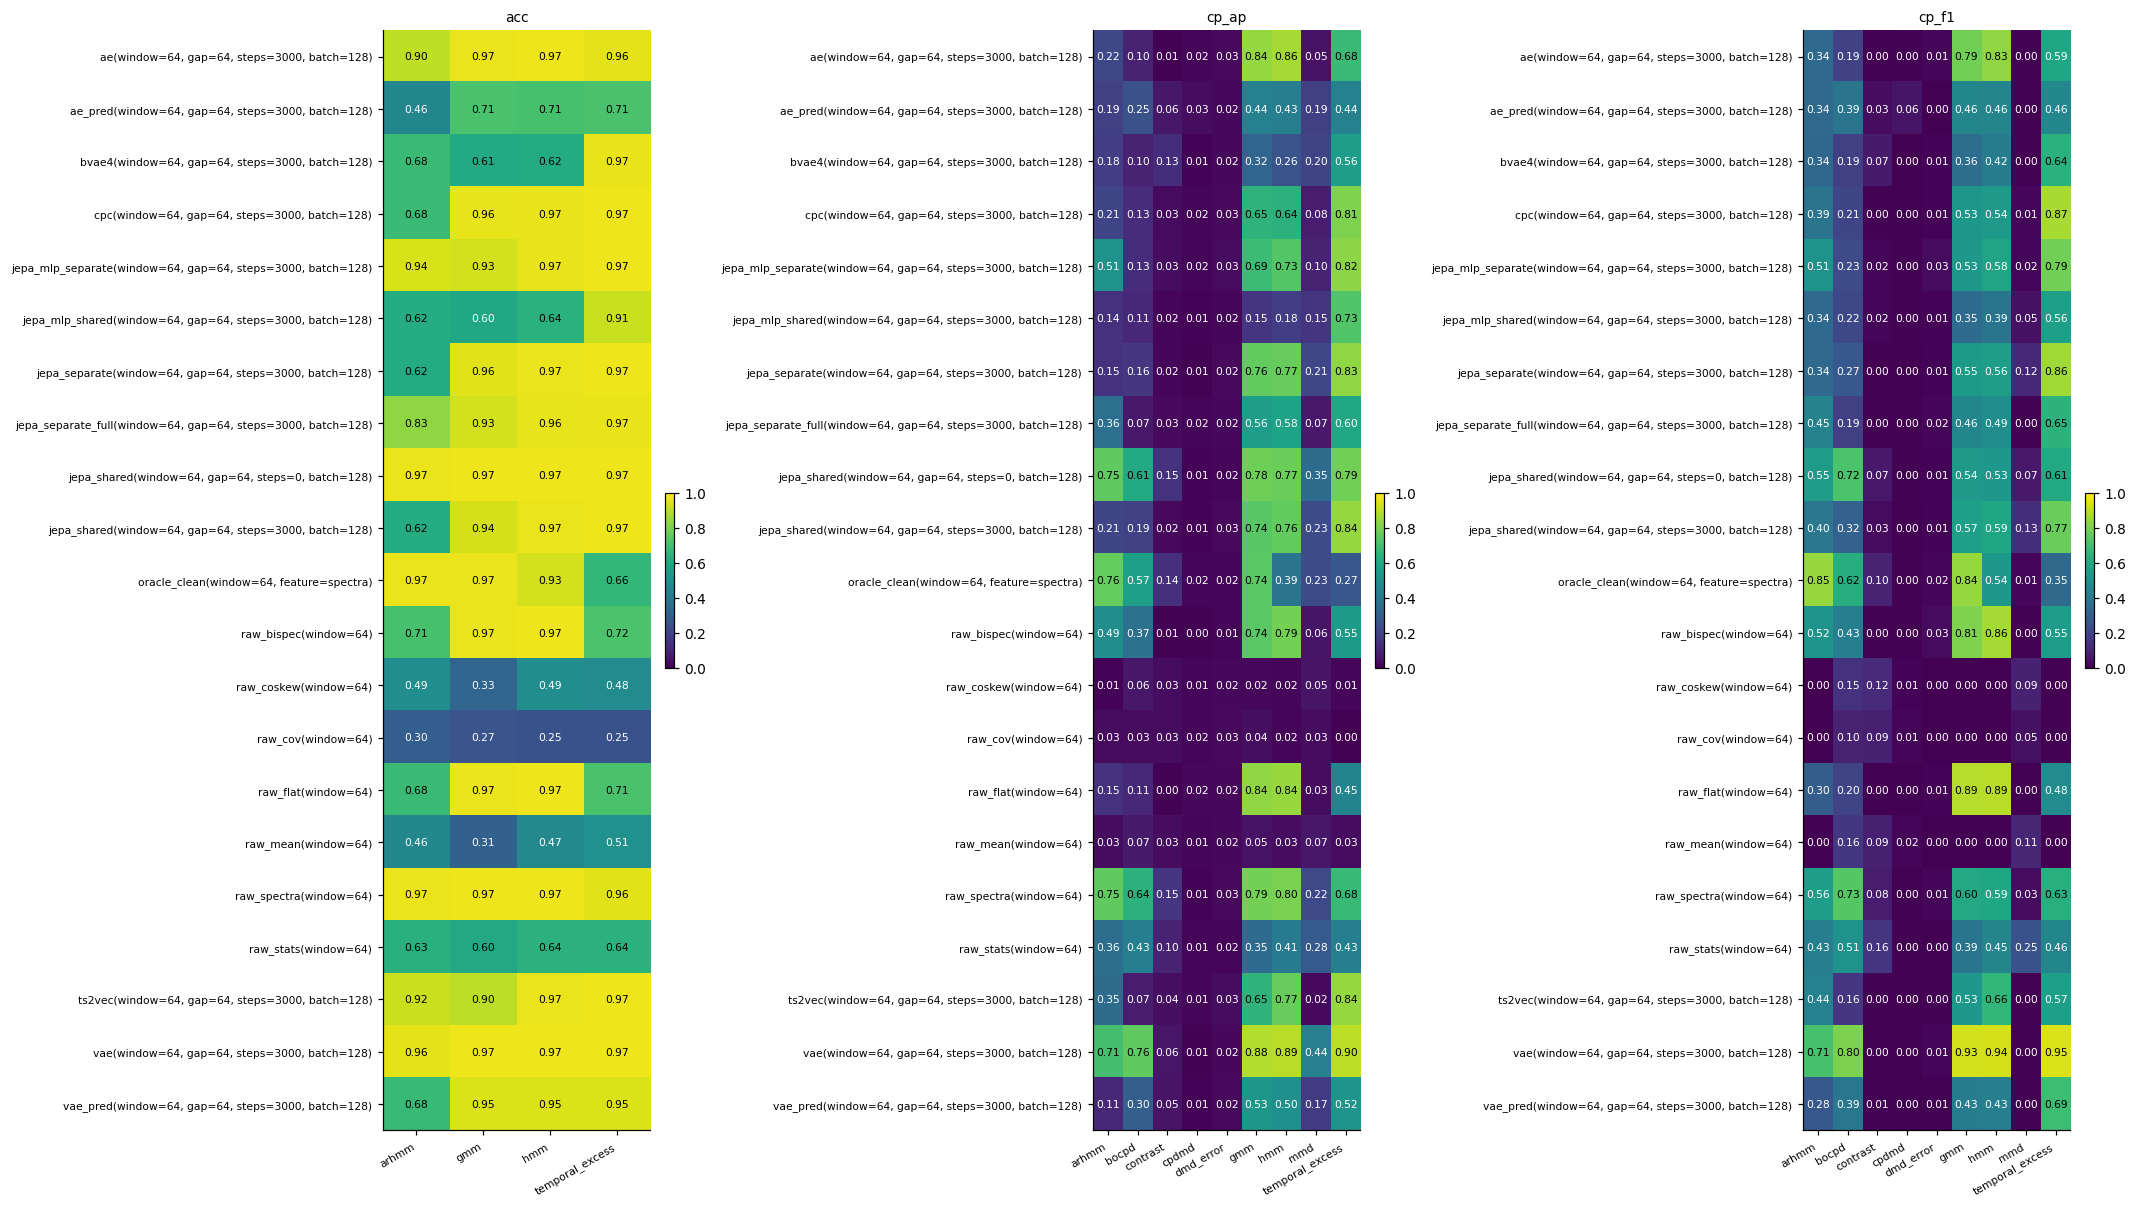

In [9]:
viz.plot_results(res, metrics=("acc", "cp_ap", "cp_f1"))

In [10]:
# best detector per feature learner (clustering accuracy, change-point AP), plus the supervised probe (diagnostic)
f_ = res[res.view == "features"]
best = pd.DataFrame({
    "acc (best clustering detector)": f_[f_.metric == "acc"].groupby("features_label").value.max(),
    "cp_ap (best detector)": f_[f_.metric == "cp_ap"].groupby("features_label").value.max(),
    "linear probe (supervised)": f_[(f_.detector == "probe") & (f_.metric == "probe_linear")].groupby("features_label").value.max(),
})
best.sort_values("acc (best clustering detector)", ascending=False).round(3)

,acc (best clustering detector),cp_ap (best detector),linear probe (supervised)
features_label,,,
"vae(window=64, gap=64, steps=3000, batch=128)",0.975,0.901,0.996
"jepa_shared(window=64, gap=64, steps=3000, batch=128)",0.974,0.842,0.993
raw_bispec(window=64),0.974,0.790,0.321
raw_flat(window=64),0.974,0.845,0.293
"ts2vec(window=64, gap=64, steps=3000, batch=128)",0.974,0.843,0.984
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.973,0.787,0.989
"ae(window=64, gap=64, steps=3000, batch=128)",0.973,0.864,0.988
raw_spectra(window=64),0.973,0.797,0.989
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.973,0.824,0.984


In [11]:
# full tables
for m in ("acc", "cp_ap", "cp_f1", "cp_covering"):
    t = f_[(f_.metric == m) & (f_.detector != "probe")].pivot_table(index="features_label", columns="detector_label", values="value")
    if len(t):
        print(m); display(t.round(3))

acc


detector_label,arhmm,gmm,hmm,temporal_excess
features_label,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.903,0.971,0.973,0.960
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.460,0.712,0.708,0.711
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.681,0.613,0.615,0.966
"cpc(window=64, gap=64, steps=3000, batch=128)",0.683,0.964,0.967,0.973
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.941,0.931,0.967,0.973
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.619,0.598,0.638,0.915
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.615,0.956,0.971,0.973
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.833,0.930,0.963,0.969
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.972,0.973,0.973,0.973


cp_ap


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.217,0.097,0.006,0.017,0.026,0.842,0.864,0.050,0.683
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.188,0.248,0.063,0.034,0.022,0.439,0.429,0.188,0.440
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.180,0.100,0.133,0.011,0.020,0.325,0.258,0.205,0.560
"cpc(window=64, gap=64, steps=3000, batch=128)",0.210,0.126,0.031,0.015,0.025,0.649,0.644,0.080,0.808
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.511,0.129,0.031,0.016,0.031,0.686,0.734,0.100,0.824
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.145,0.112,0.019,0.009,0.018,0.149,0.185,0.154,0.730
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.148,0.159,0.019,0.007,0.024,0.759,0.766,0.211,0.833
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.364,0.067,0.026,0.015,0.020,0.559,0.582,0.068,0.599
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.755,0.612,0.147,0.011,0.019,0.779,0.774,0.352,0.787


cp_f1


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.342,0.192,0.000,0.005,0.012,0.788,0.835,0.005,0.591
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.343,0.387,0.032,0.059,0.000,0.458,0.457,0.000,0.464
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.337,0.190,0.071,0.000,0.011,0.360,0.425,0.000,0.638
"cpc(window=64, gap=64, steps=3000, batch=128)",0.387,0.210,0.005,0.000,0.009,0.529,0.541,0.014,0.869
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.509,0.232,0.018,0.005,0.030,0.532,0.582,0.019,0.788
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.343,0.216,0.016,0.005,0.009,0.350,0.388,0.046,0.565
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.344,0.274,0.000,0.000,0.009,0.547,0.562,0.116,0.858
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.447,0.189,0.005,0.000,0.017,0.459,0.489,0.005,0.645
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.553,0.718,0.070,0.005,0.008,0.540,0.534,0.069,0.606


cp_covering


detector_label,arhmm,bocpd,contrast,cpdmd,dmd_error,gmm,hmm,mmd,temporal_excess
features_label,,,,,,,,,
"ae(window=64, gap=64, steps=3000, batch=128)",0.655,0.466,0.287,0.075,0.275,0.863,0.886,0.106,0.711
"ae_pred(window=64, gap=64, steps=3000, batch=128)",0.719,0.546,0.101,0.147,0.088,0.634,0.686,0.036,0.655
"bvae4(window=64, gap=64, steps=3000, batch=128)",0.711,0.508,0.138,0.078,0.323,0.548,0.665,0.036,0.841
"cpc(window=64, gap=64, steps=3000, batch=128)",0.763,0.508,0.045,0.060,0.150,0.628,0.650,0.052,0.945
"jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)",0.679,0.537,0.105,0.078,0.166,0.604,0.636,0.070,0.882
"jepa_mlp_shared(window=64, gap=64, steps=3000, batch=128)",0.598,0.554,0.188,0.090,0.145,0.528,0.565,0.091,0.681
"jepa_separate(window=64, gap=64, steps=3000, batch=128)",0.600,0.523,0.172,0.098,0.194,0.601,0.621,0.157,0.922
"jepa_separate_full(window=64, gap=64, steps=3000, batch=128)",0.667,0.550,0.112,0.067,0.176,0.581,0.602,0.056,0.869
"jepa_shared(window=64, gap=64, steps=0, batch=128)",0.617,0.887,0.153,0.086,0.215,0.608,0.621,0.113,0.672


## 5. Inspecting decisions

Below, every detector's decisions on the trained learner with the best clustering accuracy, against the truth, then the 2-D PCA of a few feature spaces coloured by the true regime.

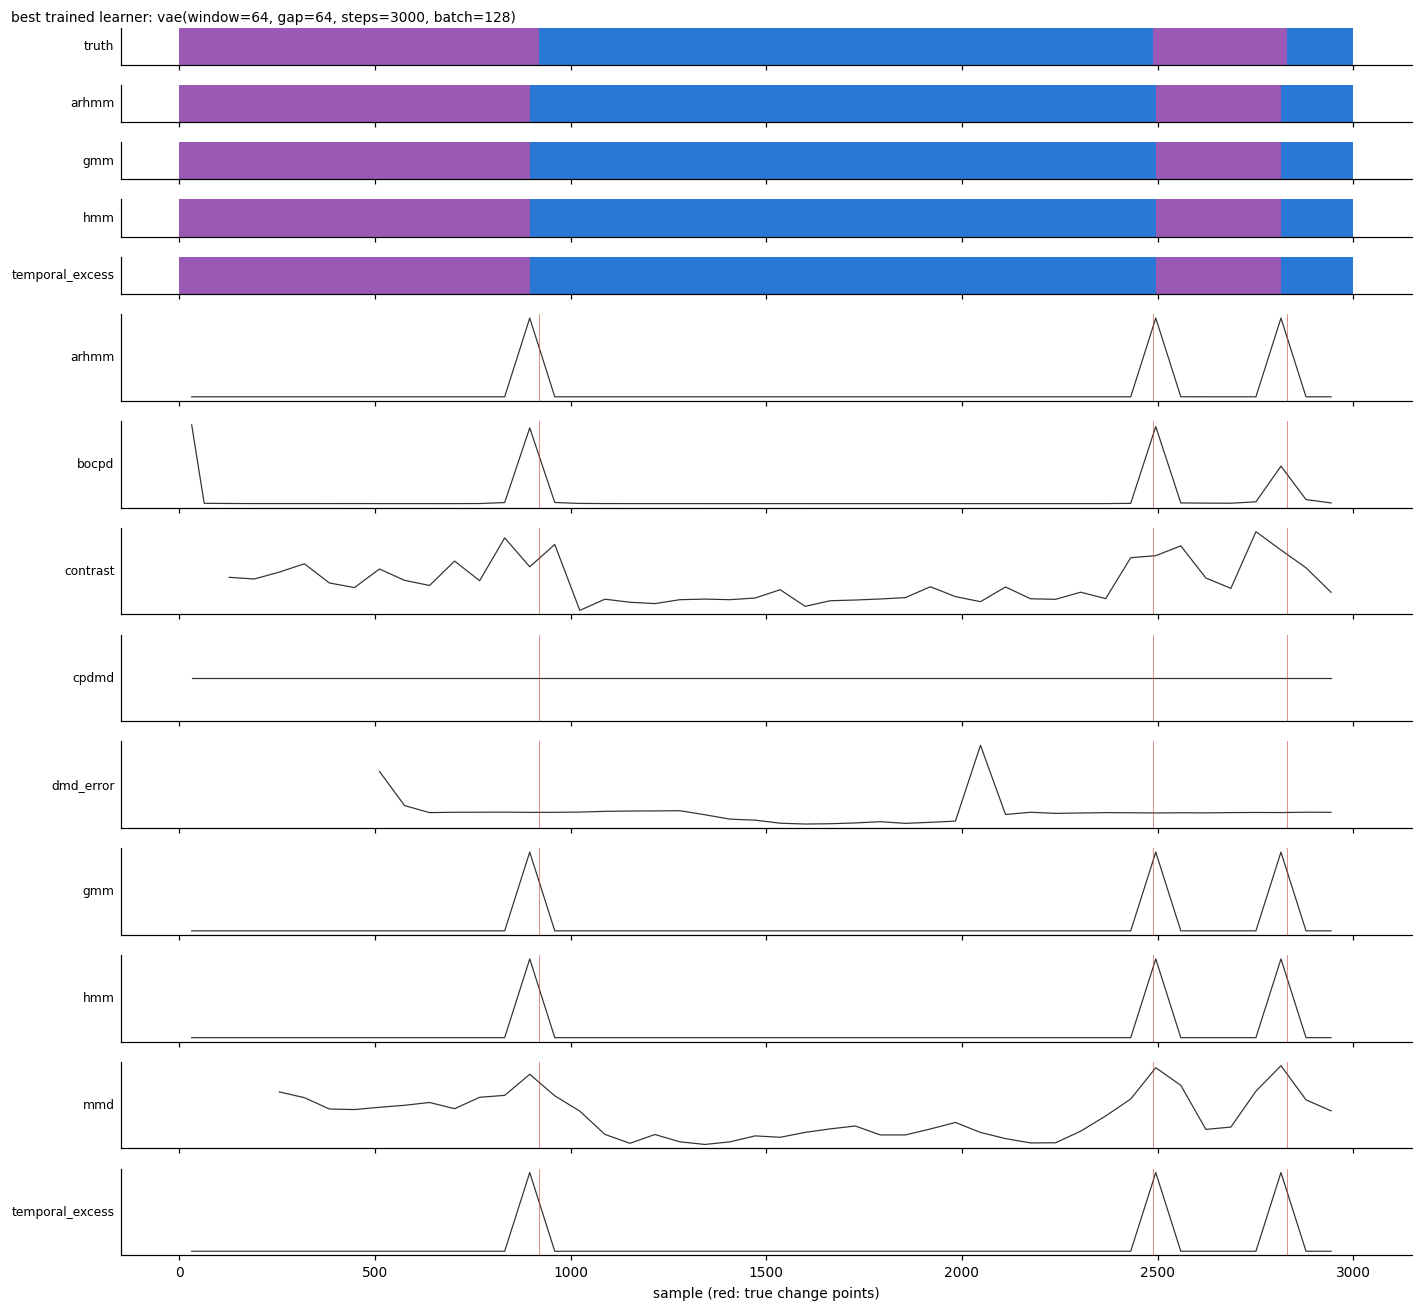

In [12]:
acc = f_[(f_.metric == "acc") & f_.features.isin([f.name for f in LEARNT])].groupby("features_label").value.max()
top = next(f for f in LEARNT if f.label() == acc.idxmax()) if len(acc) else LEARNT[0]
dec, starts = bench.decisions(top)
viz.plot_decisions(data, dec, starts, top.window, ds.K, title=f"best trained learner: {top.label()}", n=3000)

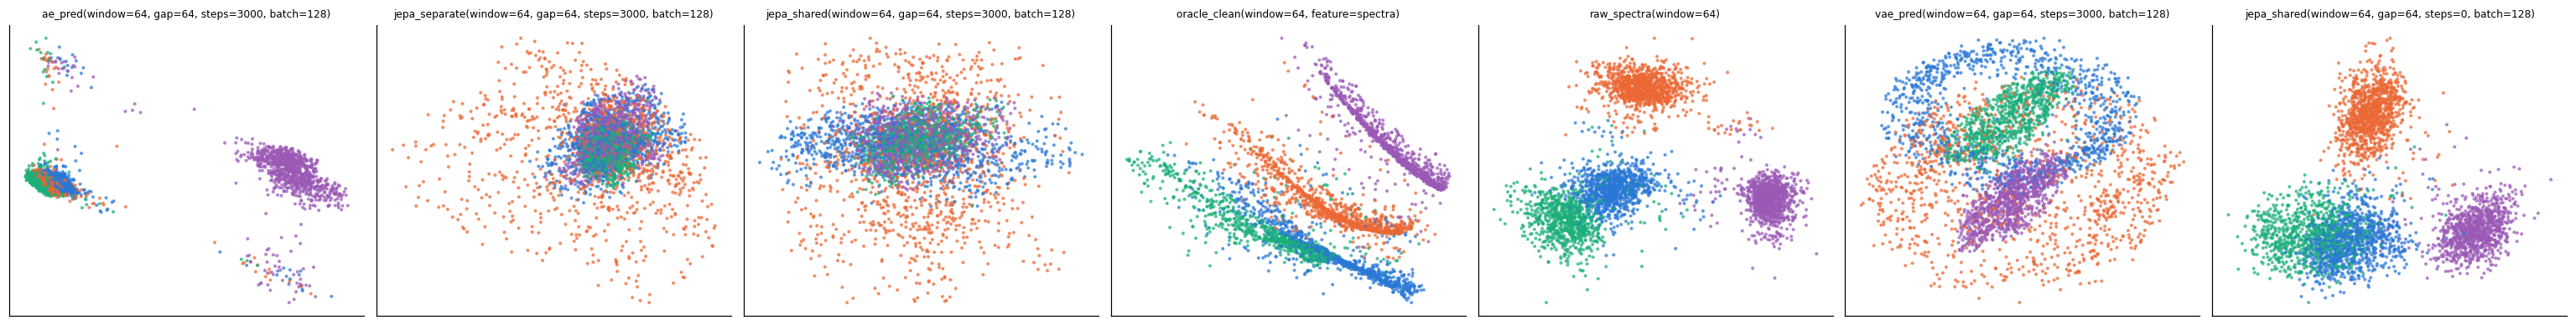

In [13]:
show = [f for f in FEATURES if f.name in ("raw_spectra", "oracle_clean", "jepa_shared", "jepa_separate", "ae_pred", "vae_pred")]
views = {f.label(): bench.features(f)[0]["features"] for f in show}
viz.plot_features(views, data, bench.features(show[0])[1], W, ds.K)

In [14]:
# separate-design JEPAs also expose their target encoder's features: the same detectors on that view
t = res[(res.view == "target") & res.metric.isin(["acc", "cp_ap"])]
if len(t):
    display(t.pivot_table(index="features_label", columns=["metric", "detector_label"], values="value").round(3))

metric                                                          acc                                cp_ap                                                                      
detector_label                                                arhmm    gmm    hmm temporal_excess  arhmm  bocpd contrast  cpdmd dmd_error    gmm    hmm    mmd temporal_excess
features_label                                                                                                                                                                
jepa_mlp_separate(window=64, gap=64, steps=3000, batch=128)   0.937  0.962  0.970           0.974  0.417  0.069    0.015  0.017     0.024  0.752  0.752  0.098           0.849
jepa_separate(window=64, gap=64, steps=3000, batch=128)       0.926  0.967  0.973           0.974  0.279  0.136    0.021  0.015     0.024  0.788  0.786  0.077           0.854
jepa_separate_full(window=64, gap=64, steps=3000, batch=128)  0.870  0.962  0.969           0.970  0.222  0.041    0.017  0.015     0.026  0.641  0.644  0.052           0.641